In [1]:
import pandas as pd
df = pd.read_csv("alumnado/clientes_formacion.csv")

In [3]:
df.shape

(3102, 22)

In [2]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 3102 entries, 0 to 3101
Data columns (total 22 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   id_cliente                3090 non-null   str    
 1   edad                      2724 non-null   float64
 2   provincia                 2998 non-null   str    
 3   situacion_laboral         3090 non-null   str    
 4   canal_captacion           3090 non-null   str    
 5   plan                      3090 non-null   str    
 6   descuento_pct             3090 non-null   float64
 7   cuota_mensual_eur         2842 non-null   float64
 8   antiguedad_meses          3090 non-null   float64
 9   accesos_30d_previos       3090 non-null   float64
 10  accesos_30d               3090 non-null   float64
 11  dias_activos_30d          3090 non-null   float64
 12  horas_uso_30d             2784 non-null   float64
 13  dias_desde_ultimo_acceso  3090 non-null   float64
 14  cursos_iniciados_30

In [5]:
df.isnull().sum()

id_cliente                    12
edad                         378
provincia                    104
situacion_laboral             12
canal_captacion               12
plan                          12
descuento_pct                 12
cuota_mensual_eur            260
antiguedad_meses              12
accesos_30d_previos           12
accesos_30d                   12
dias_activos_30d              12
horas_uso_30d                318
dias_desde_ultimo_acceso      12
cursos_iniciados_30d          12
cursos_completados_30d        12
incidencias_soporte_30d       12
satisfaccion                 258
valoracion_tutor            2850
telefono_secundario         3102
estado_cuenta_31_octubre      12
abandona                      12
dtype: int64

<Axes: >

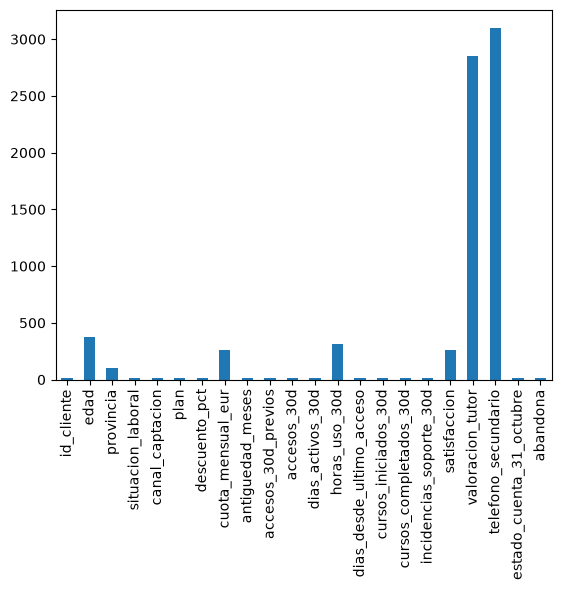

In [6]:
df.isnull().sum().plot.bar()

In [7]:
df.telefono_secundario.isnull().sum()

np.int64(3102)

In [8]:
df = df.drop(columns = "telefono_secundario")

In [9]:
df.shape

(3102, 21)

In [11]:
df.columns.tolist()

['id_cliente',
 'edad',
 'provincia',
 'situacion_laboral',
 'canal_captacion',
 'plan',
 'descuento_pct',
 'cuota_mensual_eur',
 'antiguedad_meses',
 'accesos_30d_previos',
 'accesos_30d',
 'dias_activos_30d',
 'horas_uso_30d',
 'dias_desde_ultimo_acceso',
 'cursos_iniciados_30d',
 'cursos_completados_30d',
 'incidencias_soporte_30d',
 'satisfaccion',
 'valoracion_tutor',
 'estado_cuenta_31_octubre',
 'abandona']

In [12]:
df.valoracion_tutor.isnull().sum()

np.int64(2850)

In [13]:
2850-df.shape[0]

-252

In [14]:
252/3102

0.08123791102514506

In [15]:
df = df.drop(columns="valoracion_tutor")

In [16]:
df.shape

(3102, 20)

In [17]:
df.columns

Index(['id_cliente', 'edad', 'provincia', 'situacion_laboral',
       'canal_captacion', 'plan', 'descuento_pct', 'cuota_mensual_eur',
       'antiguedad_meses', 'accesos_30d_previos', 'accesos_30d',
       'dias_activos_30d', 'horas_uso_30d', 'dias_desde_ultimo_acceso',
       'cursos_iniciados_30d', 'cursos_completados_30d',
       'incidencias_soporte_30d', 'satisfaccion', 'estado_cuenta_31_octubre',
       'abandona'],
      dtype='str')

In [18]:
df.abandona.unique()

<ArrowStringArray>
['no', 'si', nan]
Length: 3, dtype: str

In [20]:
df.abandona.value_counts(dropna=False)

abandona
no     2293
si      797
NaN      12
Name: count, dtype: int64

In [21]:
df.abandona.value_counts(dropna=False, normalize=True)

abandona
no     0.739201
si     0.256931
NaN    0.003868
Name: proportion, dtype: float64

In [23]:
df = df[df.abandona.notnull()]

In [24]:
df.abandona.value_counts(dropna=False)

abandona
no    2293
si     797
Name: count, dtype: int64

In [30]:
df.duplicated().value_counts()

False    3000
True       90
Name: count, dtype: int64

In [31]:
df.duplicated().sum()

np.int64(90)

In [32]:
df = df.drop_duplicates(keep='last')

In [33]:
df.shape

(3000, 20)

In [34]:
df.columns

Index(['id_cliente', 'edad', 'provincia', 'situacion_laboral',
       'canal_captacion', 'plan', 'descuento_pct', 'cuota_mensual_eur',
       'antiguedad_meses', 'accesos_30d_previos', 'accesos_30d',
       'dias_activos_30d', 'horas_uso_30d', 'dias_desde_ultimo_acceso',
       'cursos_iniciados_30d', 'cursos_completados_30d',
       'incidencias_soporte_30d', 'satisfaccion', 'estado_cuenta_31_octubre',
       'abandona'],
      dtype='str')

In [35]:
df.edad.describe()

count    2640.000000
mean       38.375000
std        16.186657
min       -12.000000
25%        27.000000
50%        37.000000
75%        45.000000
max       250.000000
Name: edad, dtype: float64

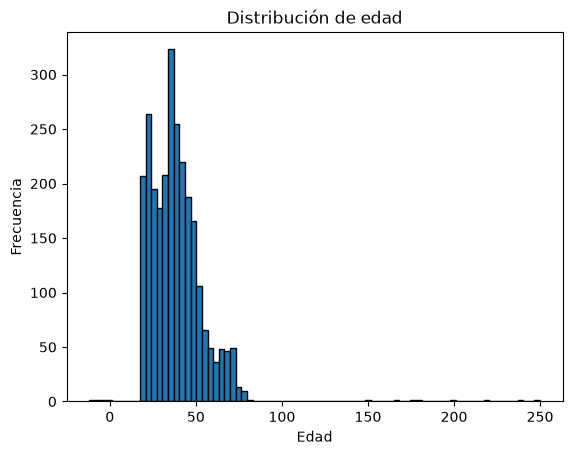

In [39]:
import matplotlib.pyplot as plt

df["edad"].plot.hist(bins=80, edgecolor="black")
plt.title("Distribución de edad")
plt.xlabel("Edad")
plt.ylabel("Frecuencia")
plt.show()

In [41]:
df[df.edad > 90].shape

(8, 20)

In [42]:
df[df.edad > 90]

,id_cliente,edad,provincia,situacion_laboral,canal_captacion,plan,descuento_pct,cuota_mensual_eur,antiguedad_meses,accesos_30d_previos,accesos_30d,dias_activos_30d,horas_uso_30d,dias_desde_ultimo_acceso,cursos_iniciados_30d,cursos_completados_30d,incidencias_soporte_30d,satisfaccion,estado_cuenta_31_octubre,abandona
274,CL002808,220.0,Barcelona,estudiante,busqueda,premium,20.0,55.2,8.0,34.0,12.0,9.0,6.98,14.0,0.0,0.0,1.0,baja,baja,si
670,CL000976,175.0,Malaga,empleado,busqueda,avanzado,0.0,39.0,4.0,31.0,10.0,10.0,4.01,13.0,2.0,1.0,1.0,alta,activa,no
1280,CL002819,250.0,NaN,empleado,redes_sociales,premium,10.0,62.1,14.0,16.0,10.0,8.0,7.68,10.0,0.0,0.0,1.0,media,activa,no
1417,CL001797,240.0,Barcelona,empleado,redes_sociales,esencial,20.0,15.2,13.0,11.0,15.0,12.0,5.17,4.0,1.0,0.0,0.0,media,activa,no
2010,CL002973,200.0,Zaragoza,empleado,recomendacion,esencial,0.0,19.0,25.0,5.0,3.0,3.0,0.72,0.0,0.0,0.0,0.0,media,activa,no
2021,CL001958,165.0,Madrid,estudiante,redes_sociales,avanzado,20.0,31.2,14.0,13.0,11.0,9.0,5.10,0.0,3.0,2.0,0.0,media,baja,si
2478,CL000768,180.0,Barcelona,empleado,busqueda,esencial,0.0,19.0,36.0,4.0,2.0,2.0,0.66,23.0,0.0,0.0,0.0,alta,baja,si
2669,CL001309,150.0,Madrid,empleado,recomendacion,esencial,0.0,19.0,25.0,12.0,8.0,8.0,2.50,3.0,2.0,1.0,0.0,alta,activa,no


In [43]:
df[df.edad <= 0]

,id_cliente,edad,provincia,situacion_laboral,canal_captacion,plan,descuento_pct,cuota_mensual_eur,antiguedad_meses,accesos_30d_previos,accesos_30d,dias_activos_30d,horas_uso_30d,dias_desde_ultimo_acceso,cursos_iniciados_30d,cursos_completados_30d,incidencias_soporte_30d,satisfaccion,estado_cuenta_31_octubre,abandona
407,CL000261,-8.0,otra,empleado,redes_sociales,esencial,20.0,15.2,3.0,12.0,6.0,6.0,1.85,10.0,1.0,0.0,0.0,baja,activa,no
1217,CL000059,-2.0,Madrid,empleado,recomendacion,avanzado,10.0,35.1,25.0,37.0,32.0,20.0,19.66,1.0,3.0,1.0,1.0,alta,activa,no
2661,CL000367,-12.0,Madrid,autonomo,redes_sociales,premium,30.0,48.3,19.0,9.0,18.0,15.0,11.54,0.0,4.0,2.0,0.0,alta,activa,no
2771,CL000838,-5.0,Valencia,autonomo,email,premium,10.0,62.1,60.0,13.0,16.0,11.0,NaN,2.0,1.0,1.0,0.0,media,activa,no


In [44]:
import numpy as np
import pandas as pd

# 1. Convertir en NaN las edades erróneas (> 90 o <= 0)
df.loc[(df['edad'] > 90) | (df['edad'] <= 0), 'edad'] = np.nan

# 2. Calcular la mediana de la edad por cada 'situacion_laboral' e imputar los NaN
# Usamos 'transform' para mantener el tamaño original del DataFrame
df['edad'] = df['edad'].fillna(
    df.groupby('situacion_laboral')['edad'].transform('median')
)

# Opcional: Si quedara algún grupo sin valores válidos, rellenar con la mediana global
df['edad'] = df['edad'].fillna(df['edad'].median())

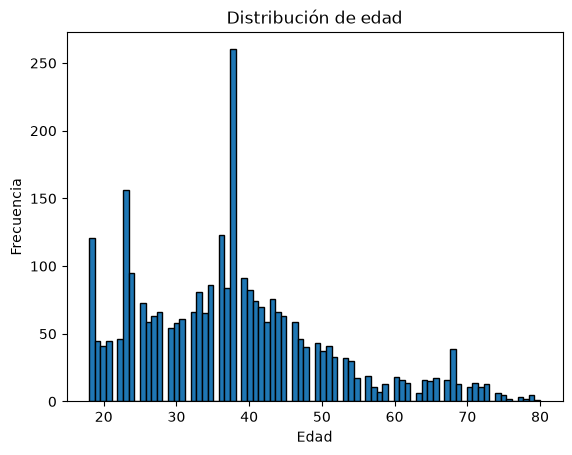

In [45]:
import matplotlib.pyplot as plt

df["edad"].plot.hist(bins=80, edgecolor="black")
plt.title("Distribución de edad")
plt.xlabel("Edad")
plt.ylabel("Frecuencia")
plt.show()

In [47]:
df.edad.isnull().sum()

np.int64(0)

In [48]:
df.edad.value_counts(dropna=False)

edad
38.0    260
23.0    156
36.0    123
18.0    121
24.0     95
       ... 
79.0      5
77.0      3
76.0      2
78.0      2
80.0      1
Name: count, Length: 64, dtype: int64

In [49]:
df.columns

Index(['id_cliente', 'edad', 'provincia', 'situacion_laboral',
       'canal_captacion', 'plan', 'descuento_pct', 'cuota_mensual_eur',
       'antiguedad_meses', 'accesos_30d_previos', 'accesos_30d',
       'dias_activos_30d', 'horas_uso_30d', 'dias_desde_ultimo_acceso',
       'cursos_iniciados_30d', 'cursos_completados_30d',
       'incidencias_soporte_30d', 'satisfaccion', 'estado_cuenta_31_octubre',
       'abandona'],
      dtype='str')

<Axes: ylabel='provincia'>

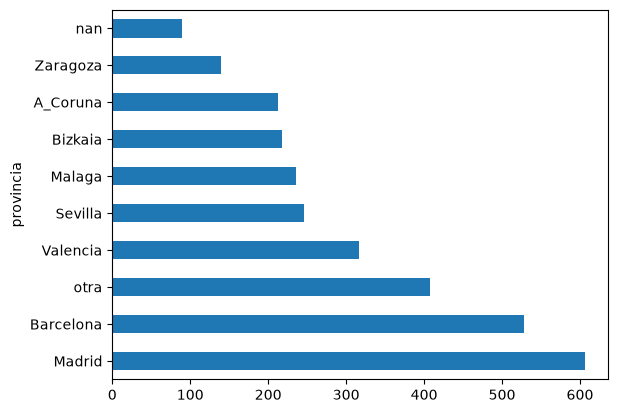

In [50]:
df.provincia.value_counts(dropna=False).plot.barh()

In [51]:
df.provincia = df.provincia.fillna("otra")

<Axes: ylabel='provincia'>

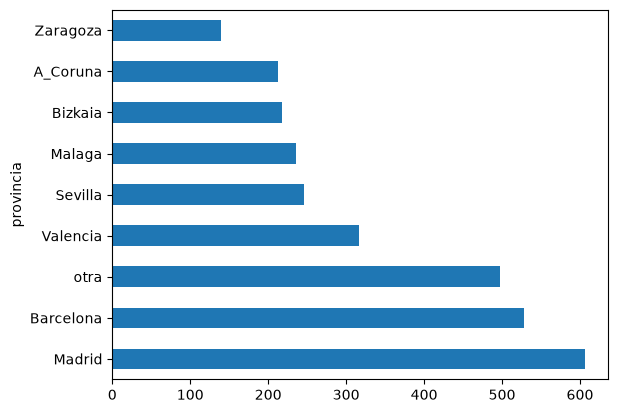

In [52]:
df.provincia.value_counts(dropna=False).plot.barh()

<Axes: ylabel='situacion_laboral'>

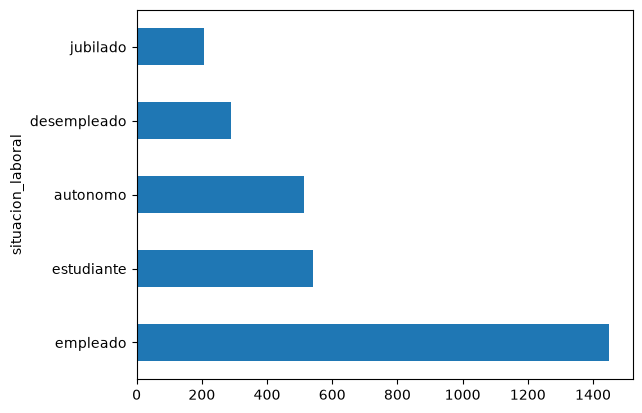

In [54]:
df.situacion_laboral.value_counts(dropna=False).plot.barh()

<Axes: ylabel='plan'>

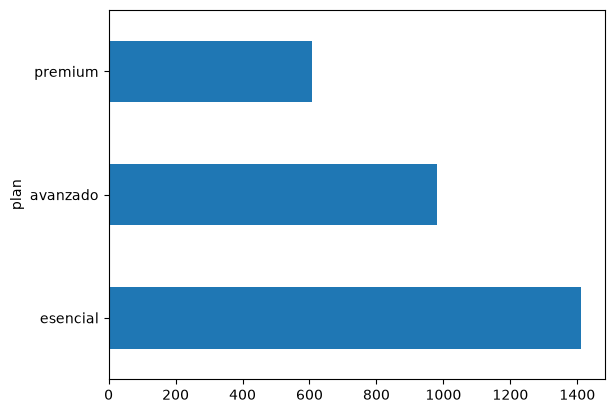

In [55]:
df.plan.value_counts(dropna=False).plot.barh()

In [56]:
df.columns

Index(['id_cliente', 'edad', 'provincia', 'situacion_laboral',
       'canal_captacion', 'plan', 'descuento_pct', 'cuota_mensual_eur',
       'antiguedad_meses', 'accesos_30d_previos', 'accesos_30d',
       'dias_activos_30d', 'horas_uso_30d', 'dias_desde_ultimo_acceso',
       'cursos_iniciados_30d', 'cursos_completados_30d',
       'incidencias_soporte_30d', 'satisfaccion', 'estado_cuenta_31_octubre',
       'abandona'],
      dtype='str')

In [57]:
df.describe()

,edad,descuento_pct,cuota_mensual_eur,antiguedad_meses,accesos_30d_previos,accesos_30d,dias_activos_30d,horas_uso_30d,dias_desde_ultimo_acceso,cursos_iniciados_30d,cursos_completados_30d,incidencias_soporte_30d
count,3000.000000,3000.000000,2760.000000,3000.000000,3000.000000,3000.000000,3000.000000,2700.000000,3000.0000,3000.000000,3000.000000,3000.000000
mean,37.859500,8.256667,44.472862,18.679667,16.797667,14.327000,9.934667,16.216667,5.7990,1.728000,0.809333,0.451333
std,13.036084,9.641496,234.053912,12.619197,12.248459,13.512449,6.564609,226.134012,8.9733,2.075761,1.196992,0.710258
min,18.000000,0.000000,-69.000000,2.000000,0.000000,0.000000,0.000000,-12.000000,0.0000,0.000000,0.000000,0.000000
25%,28.000000,0.000000,19.000000,10.000000,9.000000,5.000000,5.000000,2.050000,0.0000,0.000000,0.000000,0.000000
50%,38.000000,0.000000,31.200000,15.000000,14.000000,11.000000,9.000000,4.550000,2.0000,1.000000,0.000000,0.000000
75%,44.000000,20.000000,39.000000,25.000000,22.000000,19.000000,14.000000,8.912500,8.0000,3.000000,1.000000,1.000000
max,80.000000,30.000000,6900.000000,60.000000,129.000000,125.000000,30.000000,8000.000000,58.0000,19.000000,10.000000,5.000000


In [58]:
import pandas as pd


def estilizar_describe(df_desc):
  # Creamos un DataFrame vacío con las mismas dimensiones para almacenar los estilos CSS
  df_styles = pd.DataFrame('', index=df_desc.index, columns=df_desc.columns)

  # 1. Condición: Celdas negativas en rojo (aplica a todo el describe)
  for col in df_desc.columns:
    for idx in df_desc.index:
      val = df_desc.loc[idx, col]
      if pd.notna(val) and val < 0:
        df_styles.loc[idx, col] = 'background-color: #ff9999;'  # Rojo claro

  # 2. Condición: Celda 'max' que supere 4 veces la celda '75%' en amarillo
  if 'max' in df_desc.index and '75%' in df_desc.index:
    for col in df_desc.columns:
      val_max = df_desc.loc['max', col]
      val_75 = df_desc.loc['75%', col]
      if pd.notna(val_max) and pd.notna(val_75) and val_max > (4 * val_75):
        df_styles.loc['max', col] = 'background-color: #ffff99;'  # Amarillo

  return df_styles


# Aplicar el estilo al describe de tu DataFrame
df_styled = df.describe().style.apply(estilizar_describe, axis=None)

# Muestra el resultado (en Jupyter Notebooks se renderiza automáticamente con colores)
df_styled

,edad,descuento_pct,cuota_mensual_eur,antiguedad_meses,accesos_30d_previos,accesos_30d,dias_activos_30d,horas_uso_30d,dias_desde_ultimo_acceso,cursos_iniciados_30d,cursos_completados_30d,incidencias_soporte_30d
count,3000.000000,3000.000000,2760.000000,3000.000000,3000.000000,3000.000000,3000.000000,2700.000000,3000.000000,3000.000000,3000.000000,3000.000000
mean,37.859500,8.256667,44.472862,18.679667,16.797667,14.327000,9.934667,16.216667,5.799000,1.728000,0.809333,0.451333
std,13.036084,9.641496,234.053912,12.619197,12.248459,13.512449,6.564609,226.134012,8.973300,2.075761,1.196992,0.710258
min,18.000000,0.000000,-69.000000,2.000000,0.000000,0.000000,0.000000,-12.000000,0.000000,0.000000,0.000000,0.000000
25%,28.000000,0.000000,19.000000,10.000000,9.000000,5.000000,5.000000,2.050000,0.000000,0.000000,0.000000,0.000000
50%,38.000000,0.000000,31.200000,15.000000,14.000000,11.000000,9.000000,4.550000,2.000000,1.000000,0.000000,0.000000
75%,44.000000,20.000000,39.000000,25.000000,22.000000,19.000000,14.000000,8.912500,8.000000,3.000000,1.000000,1.000000
max,80.000000,30.000000,6900.000000,60.000000,129.000000,125.000000,30.000000,8000.000000,58.000000,19.000000,10.000000,5.000000
